In [ ]:

# %load_ext cudf.pandas # importing ext to speed up operations using GPU
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, RFE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
# from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
import os
from google.colab import files #, ai
# response = ai.generate_text("What is the capital of France?")
import warnings
warnings.filterwarnings('ignore')
import mimetypes

In [ ]:
!curl -L --fail \
  "https://raw.githubusercontent.com/SamurotTt/datasets/main/archive.zip" \
  -o archive.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  556k  100  556k    0     0  1066k      0 --:--:-- --:--:-- --:--:-- 1065k


In [ ]:
# @title
tipo, encoding = mimetypes.guess_file_type("archive.zip")
print(tipo)      # application/zip
print(encoding)  # None

application/zip
None


In [ ]:
# @title
!unzip -q 'archive.zip'

In [ ]:
# @title
# Verifique se o arquivo já foi carregado
if 'archive.zip' not in os.listdir():
    # Fazer upload apenas uma vez
    uploaded = files.upload()
else:
    print("Arquivo já carregado.")

In [ ]:
# @title
# opcional -- usei para extrair o dataset de um arquivo .zip
import zipfile

# Nome do arquivo que você carregou
zip_file = '/content/archive.zip'

# Extrair o conteúdo
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('.')
    os.rename('Malware dataset.csv', 'malware_dataset.csv')

print("Arquivos extraídos com sucesso:")
!ls

Arquivos extraídos com sucesso:
archive.zip  malware_dataset.csv  sample_data


In [ ]:
# @title
os.rename('Malware dataset.csv', 'malware_dataset.csv')

### 2. Treinamento do Modelo
Vamos dividir os dados em conjuntos de treino e teste e utilizar o algoritmo **Random Forest**.

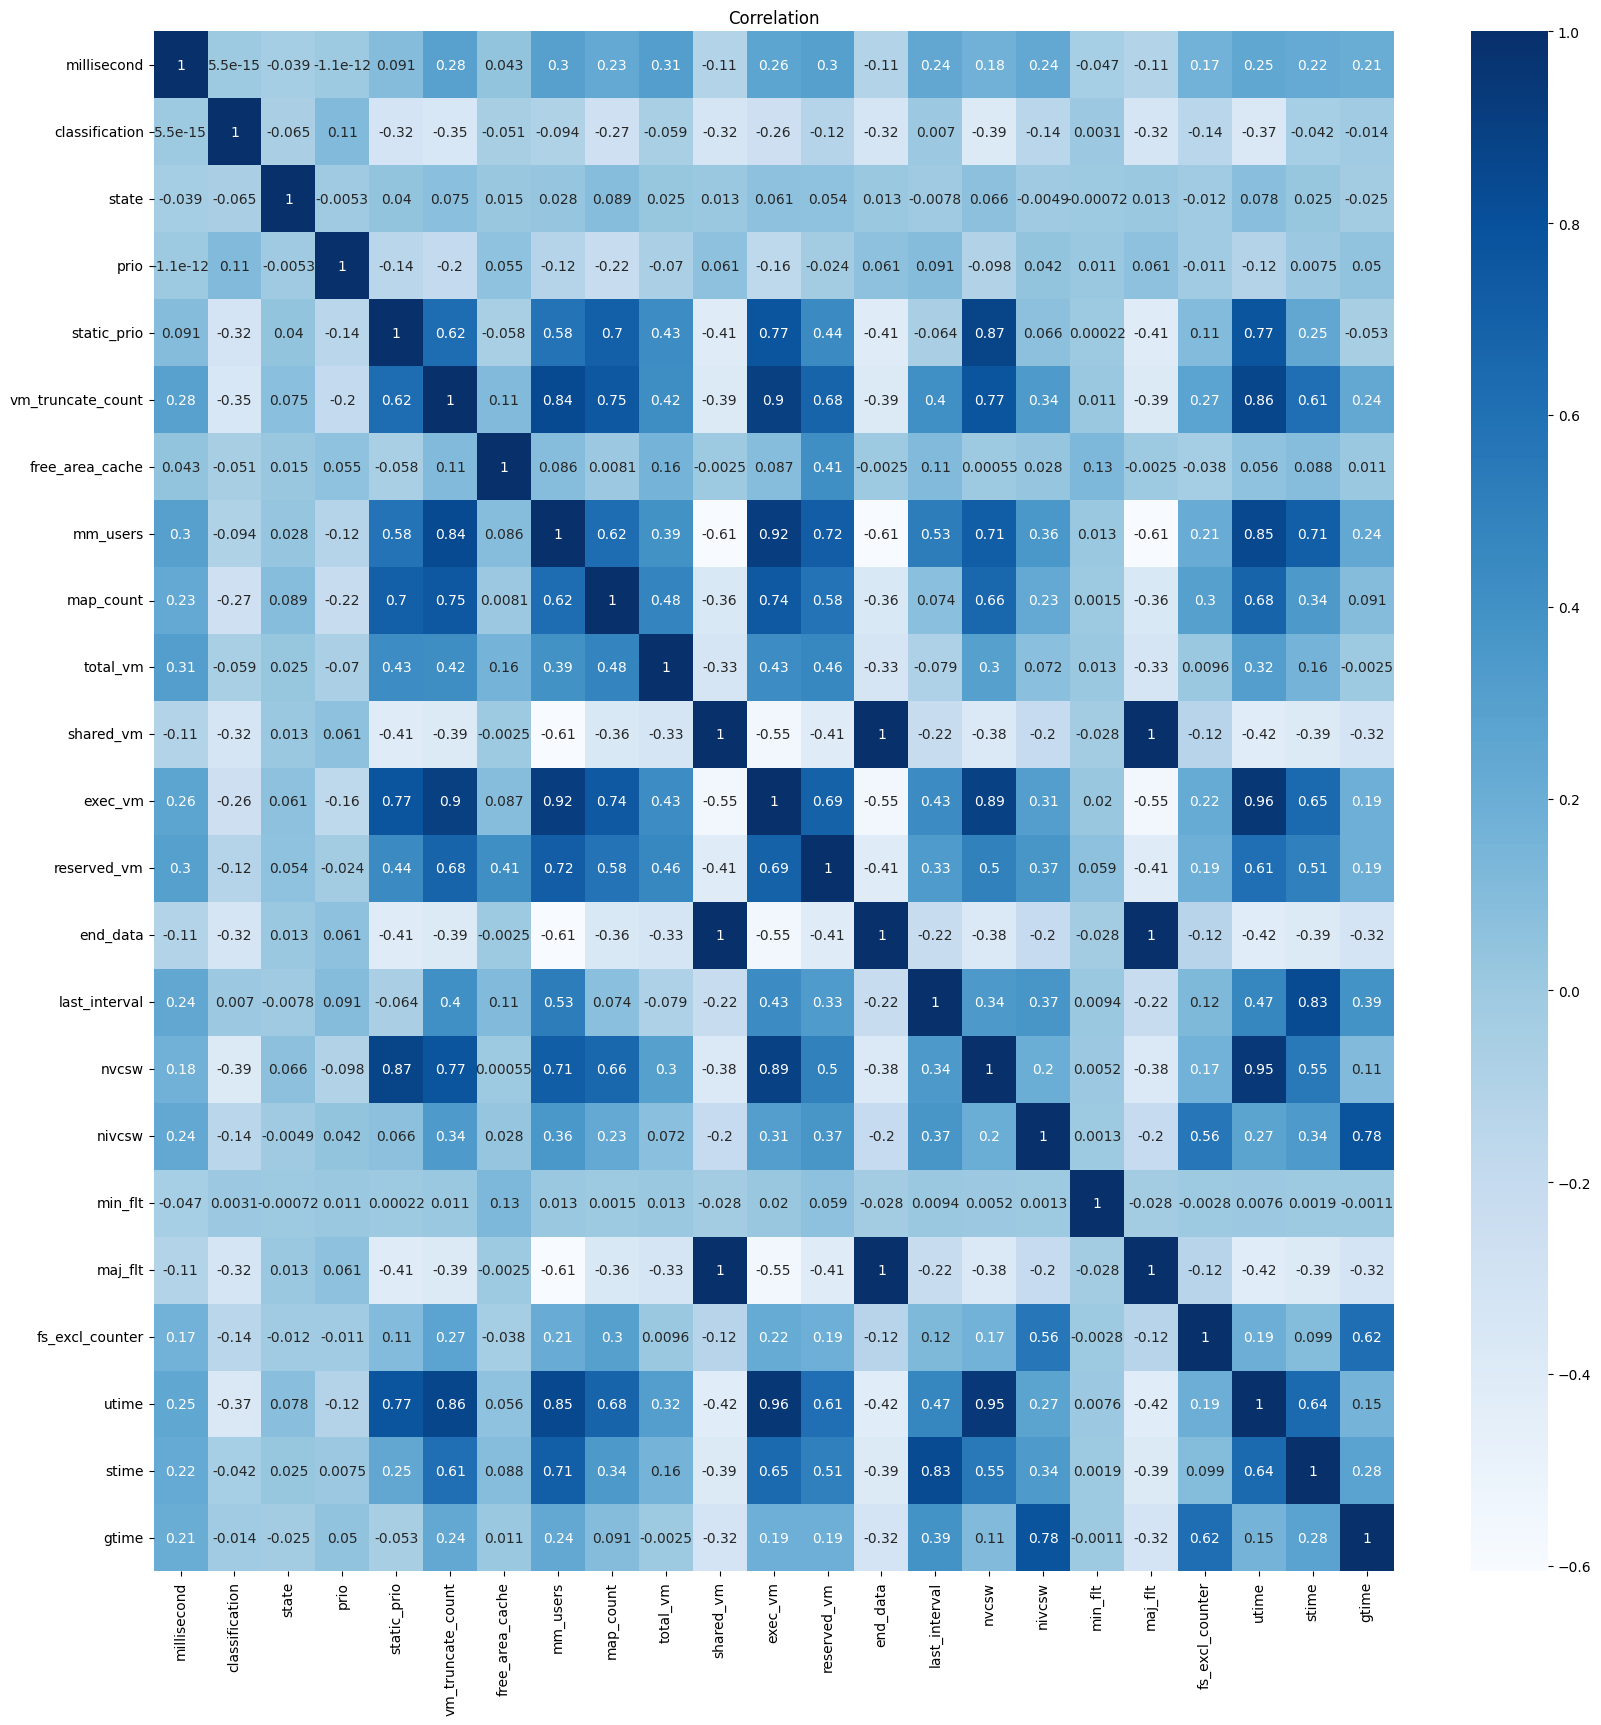

In [ ]:
from scipy.sparse import data
# TODO
ARQUIVO_DATASET = pd.read_csv('malware_dataset.csv')
#df.info()
#df.head()
# X = df.drop('is_malware', axis=1) axis é para selecionar a coluna e não a linha

# 2. Limpeza: Remover colunas de identificação e timestamp
# Assumindo que a primeira coluna é o Hash e a segunda é o millisecond
# cols_to_drop = [df.columns[0], 'millisecond']
df = ARQUIVO_DATASET.drop(columns=['hash'], errors='ignore')
# check for null values
df.isnull().sum()

# Encode classification: malware = 1, benign = 0
df['classification'] = df['classification'].map({'malware': 1, 'benign': 0})
##le = LabelEncoder()
##df_clean['classification'] = le.fit_transform(df_clean['classification'])

# removing columns with no correlation
df_new = df.drop(
    columns = [
        'usage_counter',
        'normal_prio',
        'policy',
        'vm_pgoff',
        'task_size',
        'cached_hole_size',
        'hiwater_rss',
        'nr_ptes',
        'lock',
        'cgtime',
        'signal_nvcsw'
    ],
    axis = 1
)

correlation = df_new.corr()
plt.figure(figsize = [20, 20])

sns.heatmap(
    correlation,
    annot = True,
    cmap = 'Blues'
)

plt.title("Correlation")
plt.show()


# 3. Separar Features (X) e Target (y)

X = df_new.drop(columns=['classification'])
y = df_new['classification']

# Excelente para dados tabulares de comportamento de sistema
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Extrair importâncias
importances = rf.feature_importances_
feature_names = X.columns

# Criar DataFrame para visualização
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)


In [ ]:
# @title
# ### gráficos & plotagem
# Plotar as Top 15 Features
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(15), palette='viridis')
plt.title('Top 15 Features Mais Importantes (Random Forest)')
plt.xlabel('Importância')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# --- ABORDAGEM B: Mutual Information (Filter Method) ---
# Mede a dependência não-linear entre a feature e o alvo
mi_scores = mutual_info_classif(X, y, random_state=42)
mi_df = pd.DataFrame({
    'Feature': X.columns,
    'MI_Score': mi_scores
}).sort_values(by='MI_Score', ascending=False)

print("Top 10 Features por Mutual Information:")
print(mi_df.head(10))

# --- ABORDAGEM C: Seleção Automática (RFE) ---
# Seleciona automaticamente as top 10 features usando Support Vector Machine ou Random Forest
selector = RFE(estimator=RandomForestClassifier(n_estimators=50, random_state=42), n_features_to_select=10, step=1)
selector.fit(X, y)

selected_features = X.columns[selector.support_]
print(f"\nFeatures selecionadas pelo RFE (Top 10): {list(selected_features)}")

# Métricas de Desempenho

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
# Previsões
y_pred = rf.predict(X_test)

# =========================
# MÉTRICAS
# =========================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

# =========================
# RELATÓRIO DE CLASSIFICAÇÃO
# =========================

print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

# =========================
# MATRIZ DE CONFUSÃO
# =========================

cm = confusion_matrix(y_test, y_pred)

print("\nMatriz de Confusão:")
print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf.classes_,
    yticklabels=rf.classes_
)

plt.xlabel('Classe Predita')
plt.ylabel('Classe Real')
plt.title('Matriz de Confusão - Random Forest')
plt.show()
###------------------###
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print(f"True Negative (TN): {tn}")
print(f"False Positive (FP): {fp}")
print(f"False Negative (FN): {fn}")
print(f"True Positive (TP): {tp}")

specificity = tn / (tn + fp)

print(f"Specificity: {specificity:.4f}")


## Última Versão

In [ ]:
import pandas as pd
import numpy as np
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, cohen_kappa_score, roc_auc_score, confusion_matrix
)

# 1. Preparação dos Dados (Idêntica à sua metodologia)
df = ARQUIVO_DATASET.copy()
df['classification'] = df['classification'].map({'malware': 1, 'benign': 0})

cols_constantes = [
    'usage_counter', 'normal_prio', 'policy', 'vm_pgoff', 'task_size',
    'cached_hole_size', 'hiwater_rss', 'nr_ptes', 'lock', 'cgtime', 'signal_nvcsw'
]
df = df.drop(columns=cols_constantes)

# Amostragem: 1 a cada 10 ms (10.000 linhas no total)
df = df.loc[df.groupby('hash', sort=False).cumcount().mod(10).eq(0)]

grupos = df['hash']
X = df.drop(columns=['hash', 'classification'])
y = df['classification']

# 2. Definição dos 3 Modelos (Tabela 4 do TCC)
# Nota: probability=True no SVC permite calcular o AUC de forma uniforme
modelos = {
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'SVM': SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42),
    'Regressão Logística': LogisticRegression(C=1.0, penalty='l2', max_iter=1000, random_state=42)
}

# Estrutura para guardar previsões Out-of-Fold (OOF) e métricas de todos os modelos
resultados_globais = {
    nome: {
        'metricas': [],
        'oof_preds': np.full(len(y), -1, dtype=int),
        'oof_probs': np.full(len(y), -1.0)
    } for nome in modelos
}

# 3. Validação Cruzada Agrupada (5 partições, 3 repetições = 15 avaliações por modelo)
for seed in (42, 43, 44):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)

    for nome_modelo, estimador_base in modelos.items():
        for treino, teste in cv.split(X, y, grupos):
            inicio = time.time()

            X_tr, X_te = X.iloc[treino], X.iloc[teste]
            y_tr, y_te = y.iloc[treino], y.iloc[teste]

            # O PIPELINE É A BLINDAGEM METODOLÓGICA DO SEU TCC
            # Ele garante que o RFE (com 10 features) e o Scaler sejam refeitos
            # ESTRITAMENTE com os dados de treino, evitando o Data Leakage de Fahim et al.
            pipeline = Pipeline([
                ('rfe', RFE(
                    estimator=RandomForestClassifier(n_estimators=50, random_state=seed, n_jobs=-1),
                    n_features_to_select=10,
                    step=1
                )),
                ('scaler', StandardScaler()),
                ('modelo', estimador_base.set_params(random_state=seed))
            ])

            pipeline.fit(X_tr, y_tr)

            y_pred = pipeline.predict(X_te)
            y_prob = pipeline.predict_proba(X_te)[:, 1]

            # Armazena previsões globais para a matriz de confusão real no final
            resultados_globais[nome_modelo]['oof_preds'][teste] = y_pred
            resultados_globais[nome_modelo]['oof_probs'][teste] = y_prob

            # Acumula métricas do fold em um dicionário (Pandas vai agregar isso depois)
            resultados_globais[nome_modelo]['metricas'].append({
                'acuracia': accuracy_score(y_te, y_pred),
                'precisao': precision_score(y_te, y_pred, zero_division=0),
                'recall': recall_score(y_te, y_pred, zero_division=0),
                'f1': f1_score(y_te, y_pred, zero_division=0),
                'mcc': matthews_corrcoef(y_te, y_pred),
                'kappa': cohen_kappa_score(y_te, y_pred),
                'auc': roc_auc_score(y_te, y_prob),
                'tempo': time.time() - inicio
            })

# 4. Consolidação e Relatório Científico
for nome_modelo in modelos:
    df_metricas = pd.DataFrame(resultados_globais[nome_modelo]['metricas'])
    oof_preds = resultados_globais[nome_modelo]['oof_preds']

    # Matriz de Confusão Global (Muito mais confiável que somar matrizes de folds isolados)
    tn, fp, fn, tp = confusion_matrix(y, oof_preds, labels=[0, 1]).ravel()

    # Avaliação em nível de Executável (Hash)
    df_exec = pd.DataFrame({'hash': grupos, 'real': y, 'predito': oof_preds})
    real_exec = df_exec.groupby('hash')['real'].first()
    pred_exec = df_exec.groupby('hash')['predito'].mean().ge(0.5).astype(int)
    acc_executavel = accuracy_score(real_exec, pred_exec)

    print(f"\n{'='*25} {nome_modelo.upper()} {'='*25}")
    for col in ['acuracia', 'precisao', 'recall', 'f1', 'mcc', 'kappa', 'auc', 'tempo']:
        print(f"{col.upper():15s}: {df_metricas[col].mean():.4f} ± {df_metricas[col].std():.4f}")

    print(f"{'EXECUTÁVEL':15s}: {acc_executavel:.4f}")
    print(f"Falsos Positivos (Global): {fp} | Falsos Negativos (Global): {fn}")


========================= RANDOM FOREST =========================
ACURACIA       : 0.9081 ± 0.0476
PRECISAO       : 0.9202 ± 0.0748
RECALL         : 0.9035 ± 0.0824
F1             : 0.9074 ± 0.0478
MCC            : 0.8240 ± 0.0905
KAPPA          : 0.8161 ± 0.0952
AUC            : 0.9704 ± 0.0262
TEMPO          : 3.6001 ± 0.2867
EXECUTÁVEL     : 0.9100
Falsos Positivos (Global): 411 | Falsos Negativos (Global): 469

========================= SVM =========================
ACURACIA       : 0.8737 ± 0.0476
PRECISAO       : 0.8594 ± 0.0714
RECALL         : 0.9040 ± 0.0813
F1             : 0.8771 ± 0.0463
MCC            : 0.7559 ± 0.0939
KAPPA          : 0.7473 ± 0.0952
AUC            : 0.9522 ± 0.0372
TEMPO          : 5.1549 ± 0.5791
EXECUTÁVEL     : 0.8800
Falsos Positivos (Global): 875 | Falsos Negativos (Global): 454

========================= REGRESSÃO LOGÍSTICA =========================
ACURACIA       : 0.8532 ± 0.0562
PRECISAO       : 0.8283 ± 0.0597
RECALL         : 0.8954 ± 0.0797
